In [1]:
import sys
sys.path[:0] = ["..", "../src"]

import numpy as np
import matplotlib.pyplot as plt
import config
import tools


(array([ 104.,   87.,   87.,   83.,   80.,   74.,   76.,   63.,   55.,
          42.,   39.,   45.,   37.,   31.,   23.,   22.,   32.,   21.,
          31.,   24.,   20.,   27.,   27.,   36.,   51.,   52.,   58.,
         101.,  126.,  154.,  249.,  400.,  586.,  763.,  978., 1159.,
        1320., 1301., 1172.,  988.,  721.,  514.,  335.,  216.,  131.,
          87.,   65.,   42.,   40.,   26.,   23.,   23.,   21.,   17.,
          18.,   11.,   17.,   24.,   17.,   12.,   14.,   17.,   15.,
          12.,   16.,   16.,   16.,   12.,   13.,    8.,   14.]),
 array([5100., 5105., 5110., 5115., 5120., 5125., 5130., 5135., 5140.,
        5145., 5150., 5155., 5160., 5165., 5170., 5175., 5180., 5185.,
        5190., 5195., 5200., 5205., 5210., 5215., 5220., 5225., 5230.,
        5235., 5240., 5245., 5250., 5255., 5260., 5265., 5270., 5275.,
        5280., 5285., 5290., 5295., 5300., 5305., 5310., 5315., 5320.,
        5325., 5330., 5335., 5340., 5345., 5350., 5355., 5360., 5365.,
        537

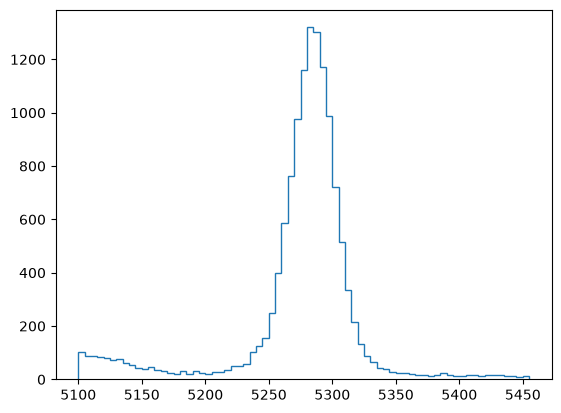

In [ ]:
mass, charge, polarity = tools.load_selected()
plt.hist(mass, bins=np.arange(5100, 5460, 5), histtype="step")


In [3]:
mass, charge, polarity = tools.load_selected()

def fwhm(masses, lo=5150, hi=5410, bin_width=4, background=None):
    edges = np.arange(lo, hi + bin_width, bin_width)
    counts, _ = np.histogram(masses, bins=edges)
    centres = 0.5 * (edges[:-1] + edges[1:])
    if background is None:                  # flat background from the outer 10 bins each side
        background = np.mean(np.r_[counts[:10], counts[-10:]])
    height = counts - background
    i_peak = np.argmax(height)
    half = height[i_peak] / 2
    i = i_peak                              # walk left until below half height
    while height[i] > half:
        i -= 1
    left = np.interp(half, [height[i], height[i + 1]], [centres[i], centres[i + 1]])
    j = i_peak                              # walk right until below half height
    while height[j] > half:
        j += 1
    right = np.interp(half, [height[j], height[j - 1]], [centres[j], centres[j - 1]])
    return right - left, centres[i_peak], left, right

w, peak, left, right = fwhm(mass)
print(f"FWHM = {w:.1f} MeV, sigma = {w / 2.355:.1f} MeV")
print(f"Peak near {peak:.0f}; half height at {left:.0f} and {right:.0f} MeV")

FWHM = 39.2 MeV, sigma = 16.6 MeV
Peak near 5284; half height at 5264 and 5304 MeV
